# Laboratory Activity 2: Can a Simple Neural Network Recognize Images?


In [ ]:
# !pip install kagglehub tensorflow scikit-learn matplotlib seaborn -q

import os, time, pathlib, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


## 1. Download the Assigned Dataset (Part 1)


In [ ]:
import kagglehub

# Downloads the dataset and returns the local path where it was extracted
dataset_path = kagglehub.dataset_download("iamsouravbanerjee/animal-image-dataset-90-different-animals")
print("Dataset downloaded to:", dataset_path)

# Explore the folder structure to find where the class subfolders actually live
for root, dirs, files in os.walk(dataset_path):
    depth = root.replace(dataset_path, "").count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + "/")


Using Colab cache for faster access to the 'animal-image-dataset-90-different-animals' dataset.
Dataset downloaded to: /kaggle/input/animal-image-dataset-90-different-animals
animal-image-dataset-90-different-animals/
  animals/
    animals/


In [ ]:
# The dataset is organized as: <dataset_path>/animals/animals/<class_name>/*.jpg
# Adjust DATA_DIR below if the printed structure above looks different on your machine.
candidates = [
    os.path.join(dataset_path, "animals", "animals"),
    os.path.join(dataset_path, "animals"),
    dataset_path,
]
DATA_DIR = next(c for c in candidates if os.path.isdir(c) and len(os.listdir(c)) > 1)
print("Using DATA_DIR:", DATA_DIR)

class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print("Number of classes found:", len(class_names))
print(class_names[:10], "...")


Using DATA_DIR: /kaggle/input/animal-image-dataset-90-different-animals/animals/animals
Number of classes found: 90
['antelope', 'badger', 'bat', 'bear', 'bee', 'beetle', 'bison', 'boar', 'butterfly', 'cat'] ...


## 2. Dataset Exploration

In [ ]:
#Dataset Characteristics + Part 1.3 Classes table
from PIL import Image

counts = {}
sample_sizes = []
for c in class_names:
    folder = os.path.join(DATA_DIR, c)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    counts[c] = len(files)
    if files:
        with Image.open(os.path.join(folder, files[0])) as im:
            sample_sizes.append(im.size)  # (width, height)

total_images = sum(counts.values())
smallest_class = min(counts, key=counts.get)
largest_class = max(counts, key=counts.get)

print(f"Number of Classes      : {len(class_names)}")
print(f"Total Number of Images : {total_images}")
print(f"Image Format           : JPG/JPEG/PNG (mixed)")
print(f"Sample Image Dimensions: {sample_sizes[:5]}")
print(f"Color Channels         : 3 (RGB)")
print(f"Smallest Class         : {smallest_class} ({counts[smallest_class]} images)")
print(f"Largest Class          : {largest_class} ({counts[largest_class]} images)")


Number of Classes      : 90
Total Number of Images : 5400
Image Format           : JPG/JPEG/PNG (mixed)
Sample Image Dimensions: [(300, 168), (976, 549), (1200, 675), (183, 276), (272, 185)]
Color Channels         : 3 (RGB)
Smallest Class         : antelope (60 images)
Largest Class          : antelope (60 images)


In [ ]:
# Per-class counts (copy into the report table)
import pandas as pd
counts_df = pd.DataFrame(sorted(counts.items()), columns=["Class Name", "Number of Images"])
counts_df.index += 1
counts_df


,Class Name,Number of Images
1,antelope,60
2,badger,60
3,bat,60
4,bear,60
5,bee,60
...,...,...
86,whale,60
87,wolf,60
88,wombat,60
89,woodpecker,60


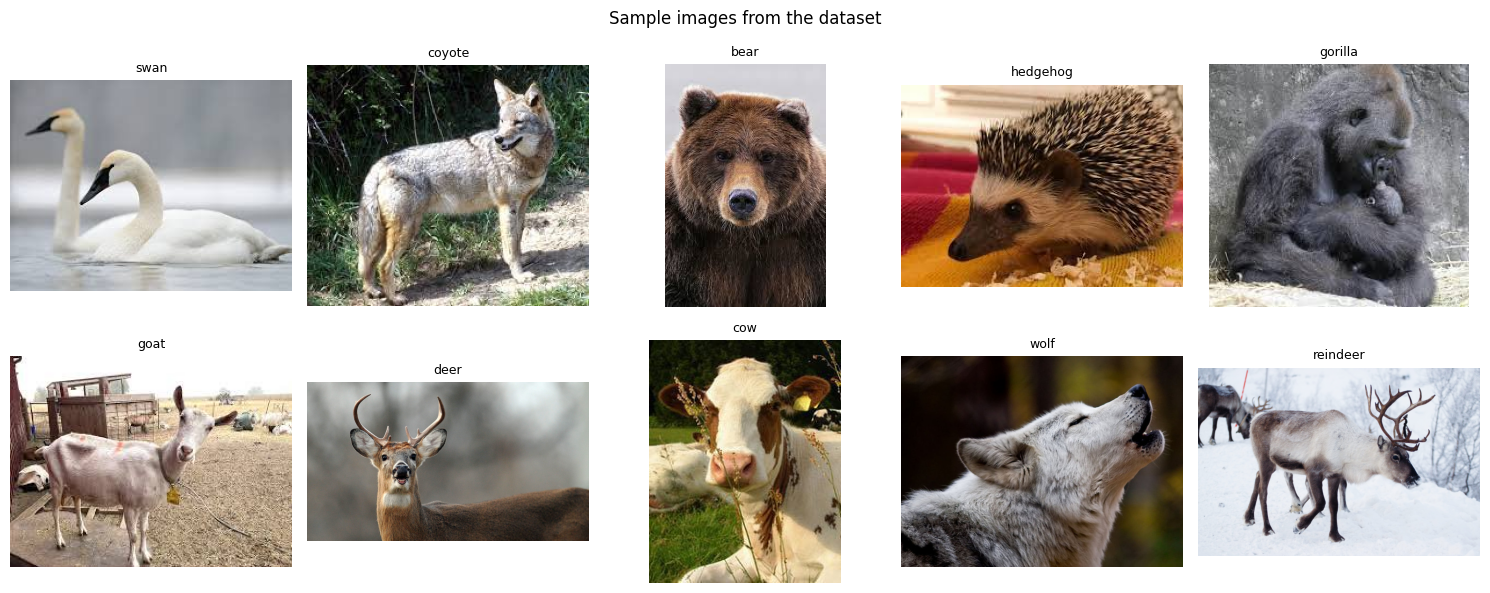

In [ ]:
# Visual sample: a few example images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample_classes = random.sample(class_names, 10)
for ax, c in zip(axes.flat, sample_classes):
    folder = os.path.join(DATA_DIR, c)
    f = [x for x in os.listdir(folder) if x.lower().endswith(('.jpg', '.jpeg', '.png'))][0]
    img = Image.open(os.path.join(folder, f))
    ax.imshow(img)
    ax.set_title(c, fontsize=9)
    ax.axis('off')
plt.suptitle("Sample images from the dataset")
plt.tight_layout()
plt.show()


## 3. Train / Validation / Test Split

In [ ]:
IMG_SIZE = (64, 64)   # baseline resolution used for the main model (Part 3-4)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

class_names = train_ds.class_names
num_classes = len(class_names)

# Split val_test_ds (20% of data) into validation (10%) and test (10%)
val_batches = tf.data.experimental.cardinality(val_test_ds)
test_ds = val_test_ds.take(val_batches // 2)
val_ds  = val_test_ds.skip(val_batches // 2)

def count_images(ds):
    return sum(x.shape[0] for x, y in ds)

n_train = count_images(train_ds)
n_val   = count_images(val_ds)
n_test  = count_images(test_ds)
n_all   = n_train + n_val + n_test

print(f"Training images  : {n_train} ({n_train/n_all:.1%})")
print(f"Validation images: {n_val} ({n_val/n_all:.1%})")
print(f"Testing images   : {n_test} ({n_test/n_all:.1%})")
print(f"Total            : {n_all}")


Found 5400 files belonging to 90 classes.
Using 4320 files for training.
Found 5400 files belonging to 90 classes.
Using 1080 files for validation.
Training images  : 4320 (80.0%)
Validation images: 536 (9.9%)
Testing images   : 544 (10.1%)
Total            : 5400


In [ ]:
# Normalize pixel values to [0, 1] and cache/prefetch for speed
normalization_layer = layers.Rescaling(1./255)

AUTOTUNE = tf.data.AUTOTUNE
def prep(ds):
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_p = prep(train_ds)
val_ds_p   = prep(val_ds)
test_ds_p  = prep(test_ds)


## 4. Simple Neural Network

In [ ]:
# Simple data augmentation - only applied to the TRAINING set
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
], name="data_augmentation")

def build_simple_nn(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Flatten(),                                    # image -> 1D vector (no Conv/Pooling)

        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(num_classes, activation='softmax'),      # Softmax output
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    return model

baseline_model = build_simple_nn(IMG_SIZE + (3,), num_classes)
baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 90)             │        23,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,449,498 (24.60 MB)

 Trainable params: 6,447,962 (24.60 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [ ]:
# Re-build the training pipeline with augmentation + shuffling (val/test stay unaugmented)
def prep(ds, training=False):
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
        ds = ds.shuffle(1000, seed=SEED)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_p = prep(train_ds, training=True)
val_ds_p   = prep(val_ds)
test_ds_p  = prep(test_ds)


In [ ]:
# Class weights - some animal classes have many more images than others,
# which by itself can look like "underfitting" on the rarer classes.
from sklearn.utils.class_weight import compute_class_weight

train_labels = np.concatenate([y.numpy() for _, y in train_ds])
class_weight_values = compute_class_weight(
    class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
class_weight_dict = dict(zip(np.unique(train_labels), class_weight_values))
print("Example class weights:", dict(list(class_weight_dict.items())[:5]))


Example class weights: {np.int32(0): np.float64(0.9230769230769231), np.int32(1): np.float64(0.9411764705882353), np.int32(2): np.float64(1.0), np.int32(3): np.float64(1.0), np.int32(4): np.float64(0.9411764705882353)}


## 5. Model Training

In [ ]:
EPOCHS = 40  # EarlyStopping will typically stop well before this if the model converges sooner

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
]

history = baseline_model.fit(
    train_ds_p,
    validation_data=val_ds_p,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks,
)


Epoch 1/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 38s 123ms/step - accuracy: 0.0299 - loss: 4.8302 - val_accuracy: 0.0560 - val_loss: 4.6466 - learning_rate: 0.0010
Epoch 2/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 12s 89ms/step - accuracy: 0.0544 - loss: 4.4200 - val_accuracy: 0.0634 - val_loss: 4.2975 - learning_rate: 0.0010
Epoch 3/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 89ms/step - accuracy: 0.0660 - loss: 4.2522 - val_accuracy: 0.0672 - val_loss: 4.2893 - learning_rate: 0.0010
Epoch 4/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.0861 - loss: 4.0936 - val_accuracy: 0.0653 - val_loss: 4.3245 - learning_rate: 0.0010
Epoch 5/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.0889 - loss: 4.0306 - val_accuracy: 0.0578 - val_loss: 4.7185 - learning_rate: 0.0010
Epoch 6/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 21s 85ms/step - accuracy: 0.0986 - loss: 3.9769 - val_accuracy: 0.0616 - val_loss: 4.5347 - learning_rate: 0.0010
Epoch 7/40
135/135 ━━━━━━━━━━━━━━━━━━━━ 21s 87ms/step - accuracy: 0.1109 - 

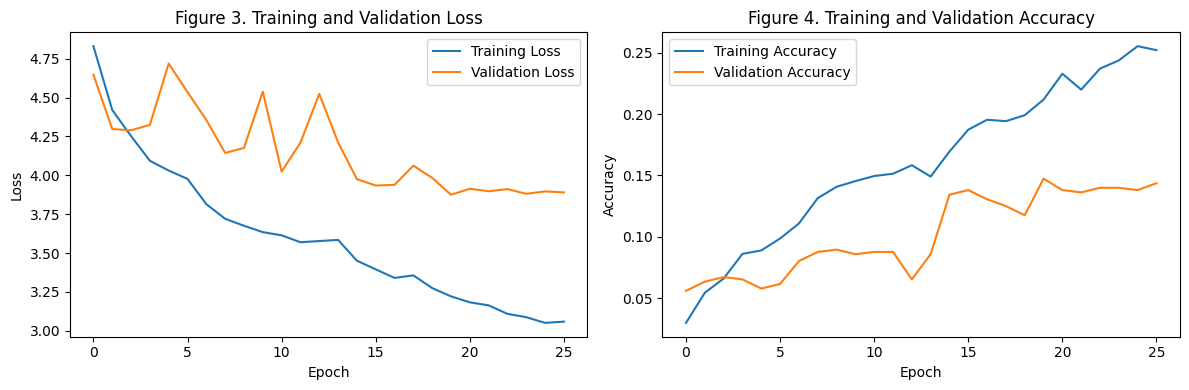

In [ ]:
# Training/Validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Training Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Figure 3. Training and Validation Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Training Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('Figure 4. Training and Validation Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()


## 6. Experiment: Effect of Image Resolution


In [ ]:
def make_datasets(img_size, batch_size=32):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR, validation_split=0.2, subset="training", seed=SEED,
        image_size=img_size, batch_size=batch_size, label_mode="int")
    val_test_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR, validation_split=0.2, subset="validation", seed=SEED,
        image_size=img_size, batch_size=batch_size, label_mode="int")
    vb = tf.data.experimental.cardinality(val_test_ds)
    test_ds = val_test_ds.take(vb // 2)
    val_ds  = val_test_ds.skip(vb // 2)

    norm = layers.Rescaling(1./255)
    def _prep(ds, training=False):
        ds = ds.map(lambda x, y: (norm(x), y), num_parallel_calls=AUTOTUNE)
        if training:
            ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
            ds = ds.shuffle(1000, seed=SEED)
        return ds.cache().prefetch(buffer_size=AUTOTUNE)
    return _prep(train_ds, training=True), _prep(val_ds), _prep(test_ds)


In [ ]:
resolutions = [(32, 32), (64, 64), (128, 128)]
EXPERIMENT_EPOCHS = 25   # EarlyStopping will cut this short once validation loss stops improving

results = []
histories = {}

for size in resolutions:
    print(f"\n=== Training at resolution {size} ===")
    tr_ds, v_ds, te_ds = make_datasets(size)
    model = build_simple_nn(size + (3,), num_classes)

    n_params = model.count_params()
    input_features = size[0] * size[1] * 3

    exp_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ]

    start = time.time()
    hist = model.fit(tr_ds, validation_data=v_ds, epochs=EXPERIMENT_EPOCHS,
                      class_weight=class_weight_dict, callbacks=exp_callbacks, verbose=1)
    elapsed = time.time() - start

    test_loss, test_acc = model.evaluate(te_ds, verbose=0)

    results.append({
        "Resolution": f"{size[0]}x{size[1]}",
        "Input Features": input_features,
        "Parameters": n_params,
        "Training Accuracy": hist.history['accuracy'][-1],
        "Validation Accuracy": hist.history['val_accuracy'][-1],
        "Test Accuracy": test_acc,
        "Training Time (s)": elapsed,
    })
    histories[f"{size[0]}x{size[1]}"] = hist

    # Keep the 64x64 model+test set as our "final" model for Part 7-8
    if size == (64, 64):
        final_model, final_test_ds = model, te_ds

results_df = pd.DataFrame(results)
results_df



=== Training at resolution (32, 32) ===
Found 5400 files belonging to 90 classes.
Using 4320 files for training.
Found 5400 files belonging to 90 classes.
Using 1080 files for validation.
Epoch 1/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 26s 49ms/step - accuracy: 0.0322 - loss: 4.8214 - val_accuracy: 0.0243 - val_loss: 5.0956 - learning_rate: 0.0010
Epoch 2/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.0493 - loss: 4.4327 - val_accuracy: 0.0560 - val_loss: 4.3456 - learning_rate: 0.0010
Epoch 3/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.0662 - loss: 4.2453 - val_accuracy: 0.0541 - val_loss: 4.4206 - learning_rate: 0.0010
Epoch 4/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.0917 - loss: 4.0967 - val_accuracy: 0.0392 - val_loss: 4.3670 - learning_rate: 0.0010
Epoch 5/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.1005 - loss: 3.9168 - val_accuracy: 0.0653 - val_loss: 4.3165 - learning_rate: 5.0000e-04
Epoch 6/25
135/135 ━━━━━━━━━━━━━━━━━━━━ 

,Resolution,Input Features,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time (s)
0,32x32,3072,1730906,0.219907,0.121269,0.143382,135.501324
1,64x64,12288,6449498,0.198611,0.113806,0.126838,293.397155
2,128x128,49152,25323866,0.244676,0.147388,0.104779,1749.077757


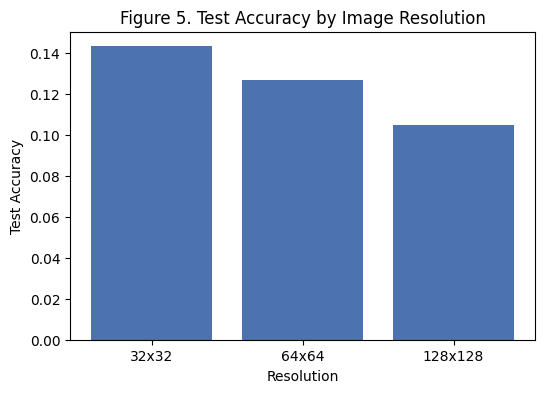

In [ ]:
# Test Accuracy by Image Resolution
plt.figure(figsize=(6, 4))
plt.bar(results_df["Resolution"], results_df["Test Accuracy"], color="#4C72B0")
plt.title("Figure 5. Test Accuracy by Image Resolution")
plt.xlabel("Resolution"); plt.ylabel("Test Accuracy")
plt.savefig('accuracy_by_resolution.png', dpi=150)
plt.show()


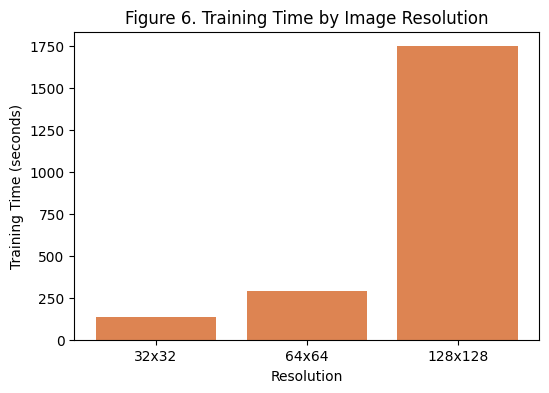

In [ ]:
#Training Time by Image Resolution
plt.figure(figsize=(6, 4))
plt.bar(results_df["Resolution"], results_df["Training Time (s)"], color="#DD8452")
plt.title("Figure 6. Training Time by Image Resolution")
plt.xlabel("Resolution"); plt.ylabel("Training Time (seconds)")
plt.savefig('time_by_resolution.png', dpi=150)
plt.show()


## 7. Model Evaluation
Using the 64×64 model as the final/best model.

In [ ]:
# Test Performance
test_loss, test_acc = final_model.evaluate(final_test_ds, verbose=0)
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


Test Loss    : 3.8835
Test Accuracy: 0.1268


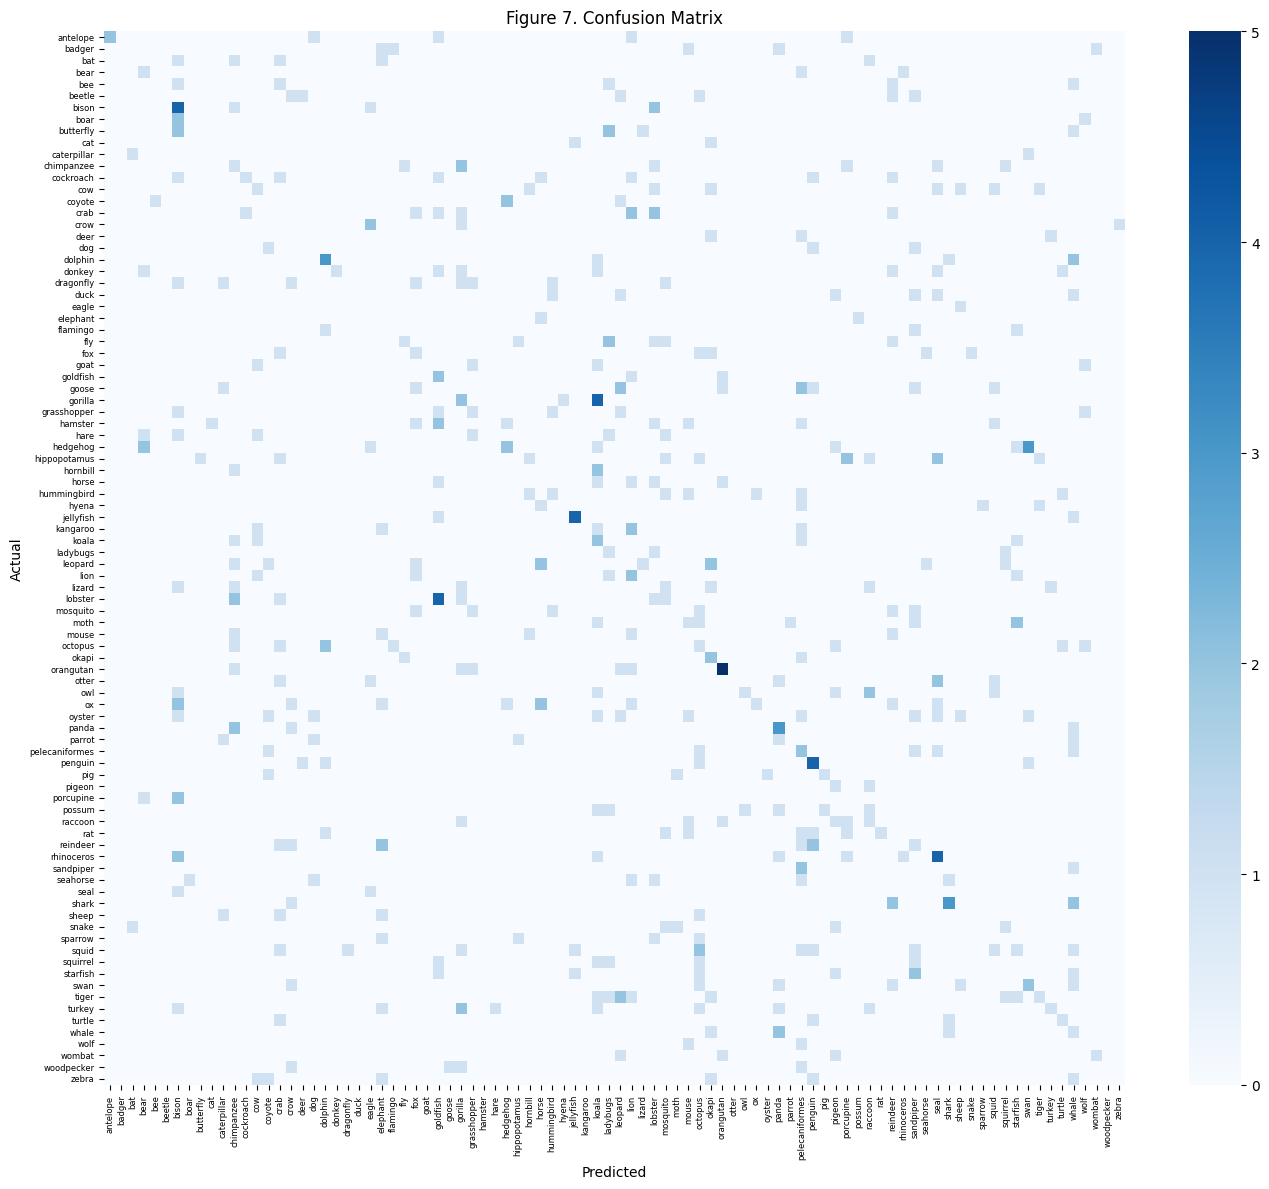

In [ ]:
#  Confusion Matrix + Part 7.3 Classification Report
y_true, y_pred = [], []
all_images = []
for images, labels in final_test_ds:
    preds = final_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))
    all_images.extend(images.numpy())

y_true, y_pred = np.array(y_true), np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Figure 7. Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=90, fontsize=6); plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


In [ ]:
# This displays all 93 rows
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(report_df)


,precision,recall,f1-score,support
antelope,1.000000,0.333333,0.500000,6.000000
badger,0.000000,0.000000,0.000000,5.000000
bat,0.000000,0.000000,0.000000,5.000000
bear,0.166667,0.333333,0.222222,3.000000
bee,0.000000,0.000000,0.000000,5.000000
beetle,0.000000,0.000000,0.000000,6.000000
bison,0.160000,0.500000,0.242424,8.000000
boar,0.000000,0.000000,0.000000,3.000000
butterfly,0.000000,0.000000,0.000000,6.000000
cat,0.000000,0.000000,0.000000,2.000000


In [ ]:
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df


,precision,recall,f1-score,support
antelope,1.000000,0.333333,0.500000,6.000000
badger,0.000000,0.000000,0.000000,5.000000
bat,0.000000,0.000000,0.000000,5.000000
bear,0.166667,0.333333,0.222222,3.000000
bee,0.000000,0.000000,0.000000,5.000000
...,...,...,...,...
woodpecker,0.000000,0.000000,0.000000,4.000000
zebra,0.000000,0.000000,0.000000,6.000000
accuracy,0.126838,0.126838,0.126838,0.126838
macro avg,0.140246,0.119851,0.103549,544.000000


In [ ]:
#Best / most difficult performing classes
per_class_f1 = report_df.loc[class_names, 'f1-score']
best_class = per_class_f1.idxmax()
worst_class = per_class_f1.idxmin()
print(f"Best performing class : {best_class}  (F1 = {per_class_f1[best_class]:.3f})")
print(f"Most difficult class  : {worst_class}  (F1 = {per_class_f1[worst_class]:.3f})")


Best performing class : jellyfish  (F1 = 0.615)
Most difficult class  : badger  (F1 = 0.000)


## 8. Prediction Analysis

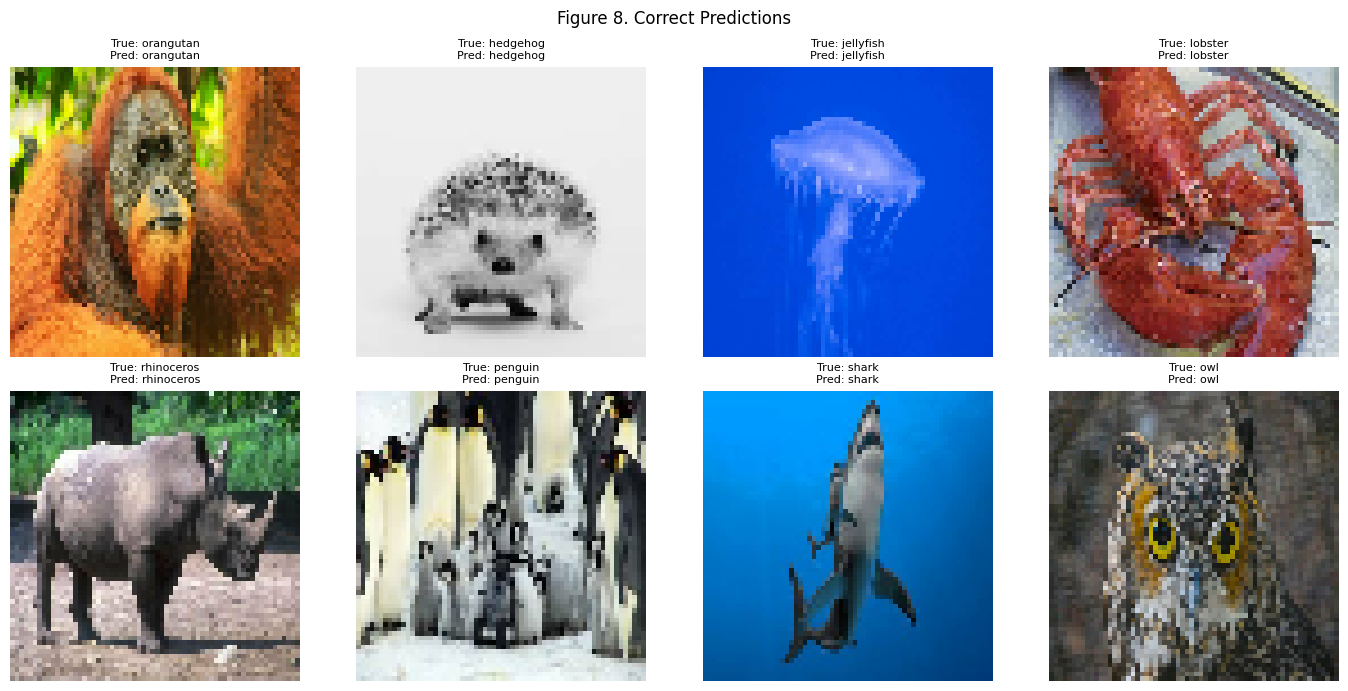

In [ ]:
#  Correct Predictions
correct_idx = np.where(y_true == y_pred)[0]
sample_correct = np.random.choice(correct_idx, min(8, len(correct_idx)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, sample_correct):
    ax.imshow(all_images[i])
    ax.set_title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}", fontsize=8)
    ax.axis('off')
plt.suptitle("Figure 8. Correct Predictions")
plt.tight_layout()
plt.savefig('correct_predictions.png', dpi=150)
plt.show()


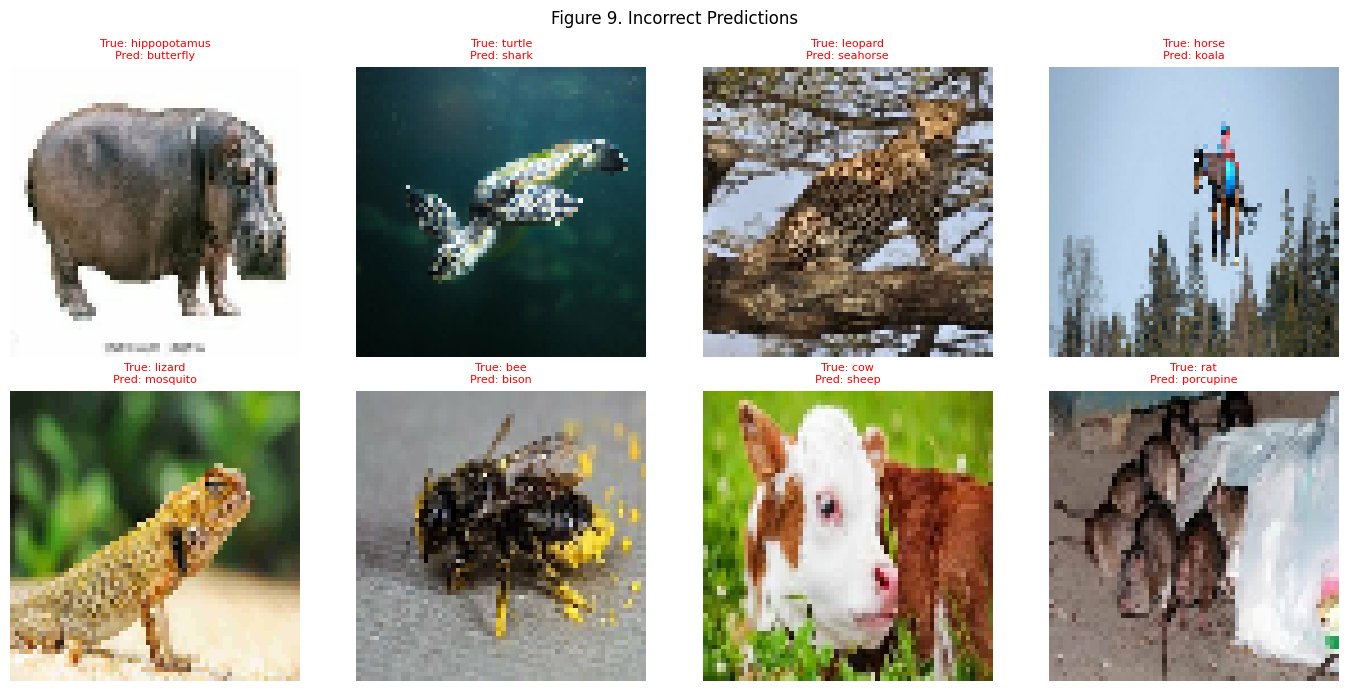

In [ ]:
# Incorrect Predictions
wrong_idx = np.where(y_true != y_pred)[0]
sample_wrong = np.random.choice(wrong_idx, min(8, len(wrong_idx)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, sample_wrong):
    ax.imshow(all_images[i])
    ax.set_title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}", fontsize=8, color='red')
    ax.axis('off')
plt.suptitle("Figure 9. Incorrect Predictions")
plt.tight_layout()
plt.savefig('incorrect_predictions.png', dpi=150)
plt.show()


In [ ]:
n_examples = min(5, len(wrong_idx))
examples = np.random.choice(wrong_idx, n_examples, replace=False)
errors_df = pd.DataFrame({
    "Image Index": examples,
    "Actual Class": [class_names[y_true[i]] for i in examples],
    "Predicted Class": [class_names[y_pred[i]] for i in examples],
})
errors_df.index += 1
errors_df


,Image Index,Actual Class,Predicted Class
1,15,dog,penguin
2,404,lizard,turkey
3,510,possum,pig
4,33,caterpillar,bat
5,145,ox,bison
